In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

target_column = "target"

if target_column not in df.columns:
    raise ValueError("The target column was not found.")

X_df = df.drop(columns=[target_column])
y_original = df[target_column].to_numpy()

X_df = pd.get_dummies(X_df, dtype=float)
X = X_df.to_numpy(dtype=float)

if not np.isfinite(X).all():
    raise ValueError("Dataset contains invalid numeric values.")

classes = np.unique(y_original)

if len(classes) != 2:
    raise ValueError("This code is designed for binary classification.")

y = np.where(y_original == classes[1], 1, -1)

print("Dataset shape:", X.shape)
print("Target classes:", classes)
print("Class distribution:", pd.Series(y_original).value_counts().to_dict())

Dataset shape: (302, 13)
Target classes: [0 1]
Class distribution: {1: 164, 0: 138}


In [15]:
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

for cls in [-1, 1]:
    indices = np.where(y == cls)[0]
    indices = rng.permutation(indices)

    if len(indices) < 2:
        raise ValueError("Each class needs at least two observations.")

    n_test = max(1, int(round(len(indices) * 0.20)))
    n_test = min(n_test, len(indices) - 1)

    test_indices.extend(indices[:n_test])
    train_indices.extend(indices[n_test:])

train_indices = rng.permutation(train_indices)
test_indices = rng.permutation(test_indices)

X_train_raw = X[train_indices]
X_test_raw = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("\nTraining samples:", len(y_train))
print("Testing samples:", len(y_test))


Training samples: 241
Testing samples: 61


In [16]:
def train_svm(X, y, learning_rate=0.005, epochs=1500, C=1.0):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    for epoch in range(epochs):
        margins = y * (X @ weights + bias)
        active = margins < 1

        if np.any(active):
            grad_w = weights - C * (
                X[active].T @ y[active]
            ) / n_samples

            grad_b = -C * np.sum(y[active]) / n_samples
        else:
            grad_w = weights.copy()
            grad_b = 0.0

        weights -= learning_rate * grad_w
        bias -= learning_rate * grad_b

    return {"weights": weights, "bias": bias}


def predict_svm(model, X):
    scores = X @ model["weights"] + model["bias"]
    return np.where(scores >= 0, 1, -1)


svm_model = train_svm(X_train, y_train)
svm_predictions = predict_svm(svm_model, X_test)

In [17]:
def knn_predict(X_reference, y_reference, X_query, k=5):
    predictions = []

    for query in X_query:
        distances = np.sqrt(
            np.sum((X_reference - query) ** 2, axis=1)
        )

        nearest = np.argsort(distances, kind="stable")[:k]
        labels = y_reference[nearest]

        count_negative = np.sum(labels == -1)
        count_positive = np.sum(labels == 1)

        if count_negative == count_positive:
            prediction = labels[0]
        else:
            prediction = 1 if count_positive > count_negative else -1

        predictions.append(prediction)

    return np.array(predictions)


knn_predictions = knn_predict(
    X_train, y_train, X_test, k=5
)

In [18]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    p_positive = np.mean(y == 1)
    p_negative = np.mean(y == -1)

    return 1 - p_positive ** 2 - p_negative ** 2


def majority_class(y):
    positives = np.sum(y == 1)
    negatives = np.sum(y == -1)

    # Deterministic tie break.
    return 1 if positives > negatives else -1


def build_tree(X, y, depth=0, max_depth=5, min_samples=5):
    node = {
        "prediction": majority_class(y),
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    if (
        depth >= max_depth
        or len(y) < 2 * min_samples
        or len(np.unique(y)) == 1
    ):
        return node

    best_score = float("inf")
    best_feature = None
    best_threshold = None
    best_left = None
    best_right = None

    parent_impurity = gini_impurity(y)

    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2

        if len(thresholds) > 30:
            positions = np.linspace(
                0, len(thresholds) - 1, 30, dtype=int
            )
            thresholds = thresholds[positions]

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            if (
                np.sum(left_mask) < min_samples
                or np.sum(right_mask) < min_samples
            ):
                continue

            left_y = y[left_mask]
            right_y = y[right_mask]

            weighted_gini = (
                len(left_y) * gini_impurity(left_y)
                + len(right_y) * gini_impurity(right_y)
            ) / len(y)

            if weighted_gini < best_score:
                best_score = weighted_gini
                best_feature = feature
                best_threshold = threshold
                best_left = left_mask
                best_right = right_mask

    if best_feature is None or best_score >= parent_impurity:
        return node

    node["feature"] = best_feature
    node["threshold"] = best_threshold

    node["left"] = build_tree(
        X[best_left], y[best_left],
        depth + 1, max_depth, min_samples
    )

    node["right"] = build_tree(
        X[best_right], y[best_right],
        depth + 1, max_depth, min_samples
    )

    return node


def predict_tree_one(node, row):
    if node["feature"] is None:
        return node["prediction"]

    if row[node["feature"]] <= node["threshold"]:
        return predict_tree_one(node["left"], row)

    return predict_tree_one(node["right"], row)


def predict_tree(tree, X):
    return np.array([
        predict_tree_one(tree, row) for row in X
    ])


tree_model = build_tree(
    X_train, y_train, max_depth=5, min_samples=5
)

tree_predictions = predict_tree(tree_model, X_test)

In [19]:
def calculate_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == -1) & (y_pred == -1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))

    accuracy = (tp + tn) / len(y_true)


    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    precision_negative = (
        tn / (tn + fn) if tn + fn > 0 else 0
    )
    recall_negative = (
        tn / (tn + fp) if tn + fp > 0 else 0
    )

    macro_precision = (precision + precision_negative) / 2
    macro_recall = (recall + recall_negative) / 2

    f1_negative = (
        2 * precision_negative * recall_negative
        / (precision_negative + recall_negative)
        if precision_negative + recall_negative > 0 else 0
    )

    macro_f1 = (f1 + f1_negative) / 2

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    }


predictions = {
    "SVM": svm_predictions,
    "k-NN": knn_predictions,
    "Decision Tree": tree_predictions
}

metrics = {}

for name, prediction in predictions.items():
    metrics[name] = calculate_metrics(y_test, prediction)

results = pd.DataFrame(metrics).T

print("\nMODEL PERFORMANCE")
print(results.round(4))


MODEL PERFORMANCE
               Accuracy  Precision  Recall  F1 Score  Macro Precision  \
SVM              0.8525     0.8000  0.9697    0.8767           0.8762   
k-NN             0.8689     0.8571  0.9091    0.8824           0.8709   
Decision Tree    0.7377     0.8148  0.6667    0.7333           0.7456   

               Macro Recall  Macro F1    TP    TN   FP    FN  
SVM                  0.8420    0.8465  32.0  20.0  8.0   1.0  
k-NN                 0.8653    0.8671  30.0  23.0  5.0   3.0  
Decision Tree        0.7440    0.7376  22.0  23.0  5.0  11.0  


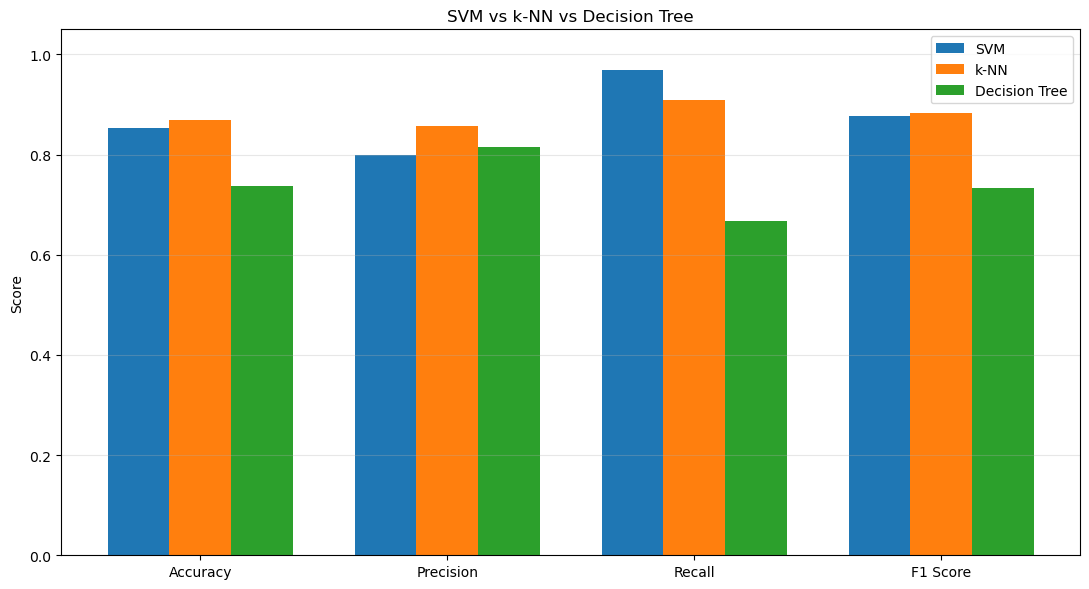

In [20]:
metric_names = ["Accuracy", "Precision", "Recall", "F1 Score"]

x_positions = np.arange(len(metric_names))
bar_width = 0.25

plt.figure(figsize=(11, 6))

for i, model_name in enumerate(predictions):
    values = [
        metrics[model_name][metric]
        for metric in metric_names
    ]

    plt.bar(
        x_positions + (i - 1) * bar_width,
        values,
        width=bar_width,
        label=model_name
    )

plt.xticks(x_positions, metric_names)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("SVM vs k-NN vs Decision Tree")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

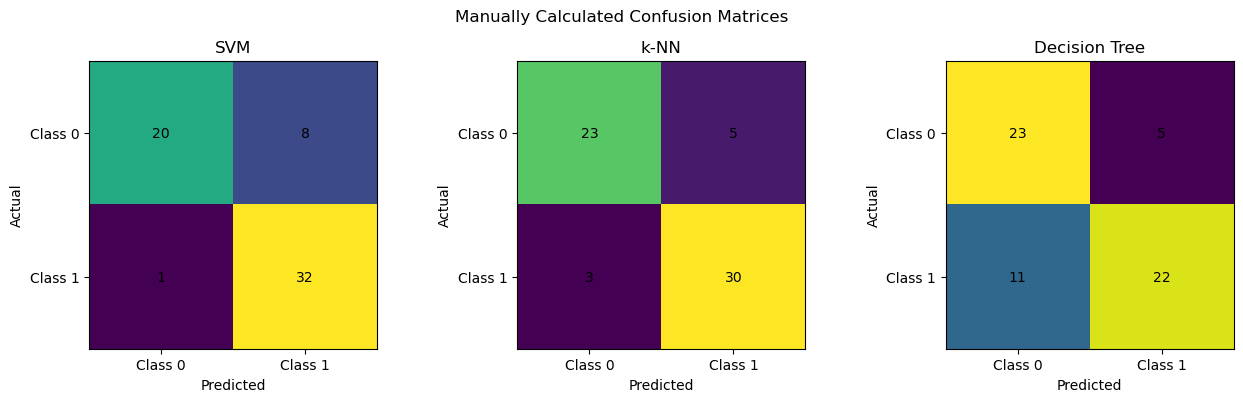

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (name, prediction) in zip(axes, predictions.items()):
    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_test, prediction):
        actual_index = 0 if actual == -1 else 1
        predicted_index = 0 if predicted == -1 else 1
        cm[actual_index, predicted_index] += 1

    ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], ["Class 0", "Class 1"])
    ax.set_yticks([0, 1], ["Class 0", "Class 1"])

    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(cm[row, col]),
                    ha="center", va="center")

plt.suptitle("Manually Calculated Confusion Matrices")
plt.tight_layout()
plt.show()

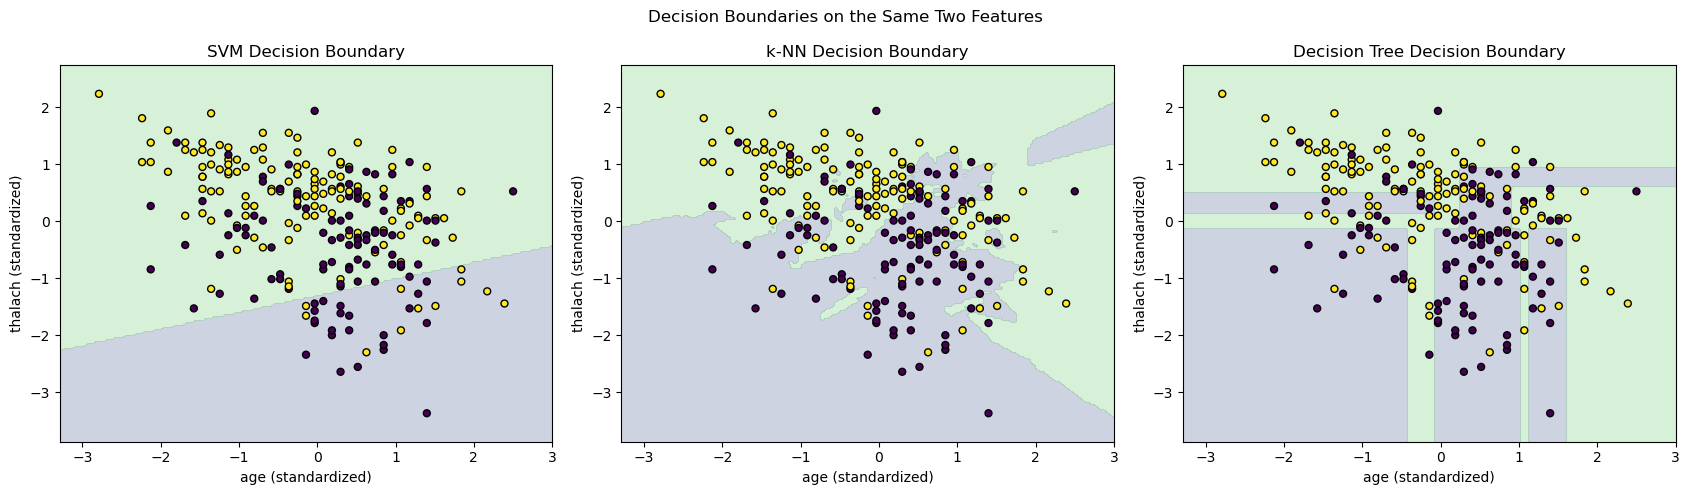

In [22]:
if "age" in X_df.columns and "thalach" in X_df.columns:
    feature_names = ["age", "thalach"]
else:
    feature_names = list(X_df.columns[:2])

if len(feature_names) < 2:
    raise ValueError("At least two features are required.")

feature_indices = [
    X_df.columns.get_loc(name) for name in feature_names
]

X_2d_raw = X[:, feature_indices]

X_2d_train_raw = X_2d_raw[train_indices]
X_2d_test_raw = X_2d_raw[test_indices]

mean_2d = X_2d_train_raw.mean(axis=0)
std_2d = X_2d_train_raw.std(axis=0)
std_2d[std_2d == 0] = 1

X_2d_train = (X_2d_train_raw - mean_2d) / std_2d
X_2d_test = (X_2d_test_raw - mean_2d) / std_2d

svm_2d = train_svm(X_2d_train, y_train)
tree_2d = build_tree(
    X_2d_train, y_train, max_depth=5, min_samples=5
)

x_min, x_max = X_2d_train[:, 0].min() - 0.5, X_2d_train[:, 0].max() + 0.5
y_min, y_max = X_2d_train[:, 1].min() - 0.5, X_2d_train[:, 1].max() + 0.5

grid_x, grid_y = np.meshgrid(
    np.linspace(x_min, x_max, 180),
    np.linspace(y_min, y_max, 180)
)

grid_points = np.column_stack([
    grid_x.ravel(), grid_y.ravel()
])

svm_grid_predictions = predict_svm(svm_2d, grid_points)
knn_grid_predictions = knn_predict(
    X_2d_train, y_train, grid_points, k=5
)
tree_grid_predictions = predict_tree(tree_2d, grid_points)

grid_predictions = [
    ("SVM", svm_grid_predictions),
    ("k-NN", knn_grid_predictions),
    ("Decision Tree", tree_grid_predictions)
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, grid_pred) in zip(axes, grid_predictions):
    Z = grid_pred.reshape(grid_x.shape)

    ax.contourf(
        grid_x, grid_y, Z,
        levels=[-1.5, 0, 1.5],
        alpha=0.25
    )

    ax.scatter(
        X_2d_train[:, 0],
        X_2d_train[:, 1],
        c=y_train,
        edgecolors="black",
        s=25
    )

    ax.set_title(name + " Decision Boundary")
    ax.set_xlabel(feature_names[0] + " (standardized)")
    ax.set_ylabel(feature_names[1] + " (standardized)")

plt.suptitle("Decision Boundaries on the Same Two Features")
plt.tight_layout()
plt.show()

In [23]:
print("\nMODEL TRADE-OFFS")
print("----------------")
print("SVM: Effective linear boundary; scaling is important.")
print("k-NN: Flexible local boundaries; prediction can be slower.")
print("Decision Tree: Interpretable rules; can overfit.")

best_accuracy = results["Accuracy"].idxmax()
best_macro_f1 = results["Macro F1"].idxmax()

print("\nHighest test accuracy:", best_accuracy)
print("Highest macro F1:", best_macro_f1)

results.to_csv("svm_knn_tree_comparison.csv")
print("\nSaved metrics to svm_knn_tree_comparison.csv")



MODEL TRADE-OFFS
----------------
SVM: Effective linear boundary; scaling is important.
k-NN: Flexible local boundaries; prediction can be slower.
Decision Tree: Interpretable rules; can overfit.

Highest test accuracy: k-NN
Highest macro F1: k-NN

Saved metrics to svm_knn_tree_comparison.csv
